# py-Pando vs R Pando 1.1.1 — pipeline-level parity

Side-by-side comparison on the canonical fixture (10x Multiome PBMC 10k, 2,000 cells, 150 target genes, 7,141 peaks; see `data/manifest.yaml`). R outputs come from `tests/r_reference_driver.R` (R 4.4.3, Pando 1.1.1 @ e8abb30, OpenBLAS 0.3.34, one BLAS thread); Python outputs from `tests/_run_candidate.py`. Both read the same normalised matrices, written once by the R driver.

## 1. Setup — the pre-registered gates

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from scipy import stats
HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "tests"))
import parity_check as pc
WORK = Path(os.environ["PYPANDO_WORK"])          # holds ref/, cand_final/, ref_xgbdiag/, ref_fn/, bench/, probe/
REF, CAND, XGBDIAG = WORK / "ref", WORK / "cand_final", WORK / "ref_xgbdiag"
manifest = yaml.safe_load((HERE.parent / "data" / "manifest.yaml").read_text())
os.environ["OPENBLAS_NUM_THREADS"] = "1"
print("algorithm class:", manifest["algorithm_class"], "| fixture:", manifest["fixture"]["description"])
pd.DataFrame([{"output": o["name"], "class": o["class"], "threshold": o["threshold"]} for o in manifest["outputs"]])

algorithm class: mixed | fixture: 2,000 cells (numpy seed 42), 150 variable target genes (Seurat vst), the peaks within 250 kb of those genes, RNA LogNormalize and peak TF-IDF computed in R and shared with Python, Pando's own bundled motifs and motif2tf table.


,output,class,threshold
0,candidate_regions,deterministic-strict,1.0
1,peaks_near_genes_signac,deterministic-strict,1.0
2,peaks_near_genes_great,deterministic-strict,1.0
3,motif_matrix,classification,"{'agreement': 0.9999, 'jaccard': 0.999}"
4,glm_keys,deterministic-strict,1.0
5,glm_coefficients,deterministic-standard,1.0
6,glm_pvalues,inference,"{'max_abs_dlog10p': 1e-06, 'spearman': 0.9999}"
7,glmnet_coefficients,ordinal,"{'pearson': 0.999, 'support_jaccard': 0.95, 'l..."
8,cvglmnet_coefficients,ordinal,"{'pearson': 0.999, 'support_jaccard': 0.95, 'l..."
9,xgb_gain,ranked,"{'spearman': 0.9, 'top10_jaccard': 0.8}"


## 2. R reference run

The driver takes about 15 minutes; its outputs and timings are read here (rerun: `Rscript tests/r_reference_driver.R data/fixture ref`).

In [2]:
rrun = json.loads((REF / "run.json").read_text())
print(rrun["R"], rrun["packages"])
pd.Series(rrun["timing"], name="R seconds").round(1)

R version 4.4.3 (2025-02-28) {'Pando': '1.1.1', 'Seurat': '5.5.1', 'Signac': '1.16.0', 'motifmatchr': '1.30.0', 'glmnet': '5.0', 'glmnetUtils': '1.1.9', 'xgboost': '3.4.2.1'}


initiate_grn                      2.2
initiate_grn_phastcons            1.3
find_motifs                     140.6
find_peaks_near_genes_Signac      0.1
find_peaks_near_genes_GREAT       0.4
infer_grn_glm                   140.6
find_modules                      0.1
infer_grn_glmnet                 48.8
infer_grn_cv.glmnet             286.1
infer_grn_xgb                   241.4
infer_grn_bagging_ridge         336.9
infer_grn_bayesian_ridge         24.6
Name: R seconds, dtype: float64

## 3. Python candidate run

(`python tests/_run_candidate.py ref cand hg38.fa`.) Timings from the runs that produced `cand_final`; the glm timing is the cached-QR benchmark (`tests/bench_infer_grn.py`).

In [3]:
ptime = {}
for d in ("cand2", "cand3", "cand4", "cand5"):
    f = WORK / d / "run.json"
    if f.exists():
        ptime.update(json.loads(f.read_text())["timing"])
bench = {p.stem: json.loads(p.read_text()) for p in (WORK / "bench").glob("*.json")}
ptime["infer_grn_glm"] = bench["glm_blas_qr_cached"]["wall_clock_mean_s"]
pd.Series(ptime, name="Python seconds").round(1)

initiate_grn                     14.9
find_motifs                     103.5
find_peaks_near_genes_Signac      0.2
find_peaks_near_genes_GREAT      18.1
infer_grn_glmnet                 76.2
infer_grn_cv.glmnet             483.3
infer_grn_xgb                   548.4
infer_grn_bagging_ridge         783.9
infer_grn_bayesian_ridge        104.6
infer_grn_glm                   121.1
Name: Python seconds, dtype: float64

## 4. Per-output parity

The gates are computed by `tests/parity_check.py` with the thresholds read from the manifest.

In [4]:
res = pc.main(REF, CAND)

PASS  candidate_regions: {"identical": true, "n_ref": 8127, "n_cand": 8127}
PASS  candidate_regions_phastcons: {"identical": true, "n_ref": 7130, "n_cand": 7130}
PASS  peaks_near_genes_signac: {"identical": true, "n_ref": 198776, "n_cand": 198776}
PASS  peaks_near_genes_great: {"identical": true, "n_ref": 96699, "n_cand": 96699}
PASS  motif_matrix: {"agreement": 1.0, "jaccard": 1.0, "n_diff": 0, "n_ref": 1240962, "n_cand": 1240962, "tfs_use_identical": true}
PASS  glm_keys: {"identical": true, "n_ref": 24642, "n_cand": 24642}
PASS  glm_coefficients: {"max_normalised_error": {"estimate": 9.791269464166968e-07, "std_err": 7.62226839598076e-07, "statistic": 9.195519709012728e-07, "corr": 7.835080265876213e-06, "gof_rsq": 4.6011063320287575e-07, "gof_nvariables": 0.0}}
PASS  glm_pvalues: {"max_abs_dlog10p": 4.014566457044566e-13, "max_abs_dlog10padj": 3.9479530755670567e-13, "spearman": 0.9999999999987971, "nan_pattern_identical": true}
PASS  modules: {"mean_jaccard": 1.0, "tf_set_jaccard"

### Candidate regions, peak-to-gene windows, motif matrix (deterministic)

In [5]:
rows = [("candidate regions", res["candidate_regions"]["n_ref"], res["candidate_regions"]["identical"]),
        ("candidate regions (phastCons)", res["candidate_regions_phastcons"]["n_ref"], res["candidate_regions_phastcons"]["identical"]),
        ("Signac windows (hits)", res["peaks_near_genes_signac"]["n_ref"], res["peaks_near_genes_signac"]["identical"]),
        ("GREAT domains (hits)", res["peaks_near_genes_great"]["n_ref"], res["peaks_near_genes_great"]["identical"]),
        ("motif matches", res["motif_matrix"]["n_ref"], res["motif_matrix"]["n_diff"] == 0)]
pd.DataFrame(rows, columns=["output", "R count", "identical"])

,output,R count,identical
0,candidate regions,8127,True
1,candidate regions (phastCons),7130,True
2,Signac windows (hits),198776,True
3,GREAT domains (hits),96699,True
4,motif matches,1240962,True


### glm network (deterministic + inference)

{'glm_keys': {'identical': True,
  'n_ref': 24642,
  'n_cand': 24642,
  'pass': True},
 'glm_coefficients': {'max_normalised_error': {'estimate': 9.791269464166968e-07,
   'std_err': 7.62226839598076e-07,
   'statistic': 9.195519709012728e-07,
   'corr': 7.835080265876213e-06,
   'gof_rsq': 4.6011063320287575e-07,
   'gof_nvariables': 0.0},
  'pass': True},
 'glm_pvalues': {'max_abs_dlog10p': 4.014566457044566e-13,
  'max_abs_dlog10padj': 3.9479530755670567e-13,
  'spearman': 0.9999999999987971,
  'nan_pattern_identical': True,
  'pass': True}}

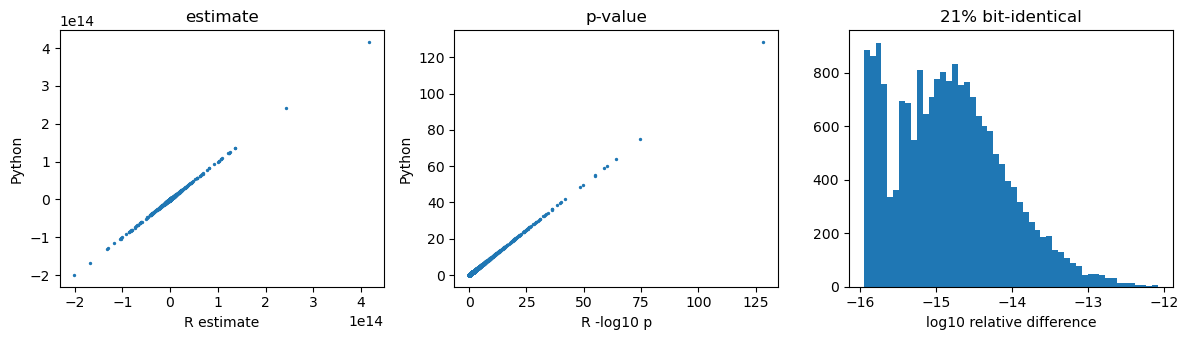

In [6]:
r = pc._read_ref_coefs(REF, "glm"); cdf = pd.read_csv(CAND / "coefs_glm.tsv", sep="\t")
m = r.merge(cdf, on=["target", "tf", "region"], suffixes=("_r", "_c"))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].scatter(m.estimate_r, m.estimate_c, s=2); ax[0].set(xlabel="R estimate", ylabel="Python", title="estimate")
lr, lc = -np.log10(m.pval_r), -np.log10(m.pval_c)
ax[1].scatter(lr, lc, s=2); ax[1].set(xlabel="R -log10 p", ylabel="Python", title="p-value")
rel = np.abs(m.estimate_r - m.estimate_c) / np.abs(m.estimate_r)
ax[2].hist(np.log10(rel[rel > 0]), bins=50); ax[2].set(xlabel="log10 relative difference", title=f"{(rel == 0).mean():.0%} bit-identical")
fig.tight_layout()
{k: res[k] for k in ("glm_keys", "glm_coefficients", "glm_pvalues")}

### Modules (classification)

In [7]:
res["modules"]

{'mean_jaccard': 1.0, 'tf_set_jaccard': 1.0, 'n_modules': 104, 'pass': True}

### glmnet and cv.glmnet (ordinal)

{'glmnet_coefficients': {'pearson': 0.9998509922559252,
  'support_jaccard': 0.9989778534923339,
  'lambda_rel_max': 1.6662450192255651e-13,
  'frac_targets_same_lambda': 1.0,
  'n_targets_ref': 145,
  'n_targets_cand': 145,
  'max_abs_estimate_diff': 0.15575658866725517,
  'rsq_max_abs_diff': 4.8244392519491974e-05,
  'pass': True},
 'cvglmnet_coefficients': {'pearson': 1.0,
  'support_jaccard': 1.0,
  'lambda_rel_max': 9.667473628344586e-14,
  'frac_targets_same_lambda': 1.0,
  'n_targets_ref': 145,
  'n_targets_cand': 145,
  'max_abs_estimate_diff': 4.954370247389761e-14,
  'rsq_max_abs_diff': 1.9539925233402755e-14,
  'pass': True}}

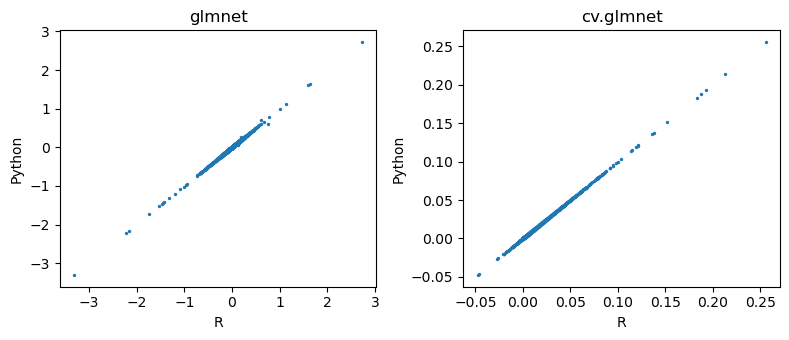

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, m_ in zip(ax, ("glmnet", "cv.glmnet")):
    r = pc._read_ref_coefs(REF, m_); cdf = pd.read_csv(CAND / f"coefs_{m_}.tsv", sep="\t")
    mm = pc._merge(r, cdf, ["estimate"]).fillna({"estimate_r": 0, "estimate_c": 0})
    a.scatter(mm.estimate_r, mm.estimate_c, s=2); a.set(xlabel="R", ylabel="Python", title=m_)
fig.tight_layout()
{k: res[k] for k in ("glmnet_coefficients", "cvglmnet_coefficients")}

### xgb (ranked)

Against the installed R (xgboost 3.4.2.1) and against the same R run with Pando's `params` honoured (`PANDO_XGB_HONOUR_PARAMS=1`, which swaps `xgboost()` for `xgb.train` with Pando's `max_depth = 3, eta = 0.01`): xgboost >= 3 changed the R `xgboost()` interface and drops the `params` list Pando passes, so the installed reference trains with depth 6 and learning rate 0.3.

,median_spearman,median_top10_jaccard,n_targets,pass
installed R,0.814649,0.666667,146,False
params honoured,1.0,1.0,146,True


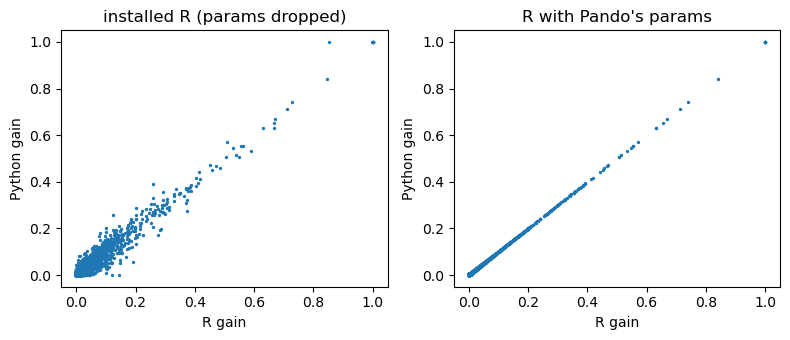

In [9]:
diag = pc.gate_xgb(XGBDIAG, CAND)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, ref, title in zip(ax, (REF, XGBDIAG), ("installed R (params dropped)", "R with Pando's params")):
    r = pc._read_ref_coefs(ref, "xgb"); cdf = pd.read_csv(CAND / "coefs_xgb.tsv", sep="\t")
    mm = pc._merge(r, cdf, ["gain"]).fillna({"gain_r": 0, "gain_c": 0})
    a.scatter(mm.gain_r, mm.gain_c, s=2); a.set(xlabel="R gain", ylabel="Python gain", title=title)
fig.tight_layout()
pd.DataFrame({"installed R": res["xgb_gain"], "params honoured": diag}).T

### bagging ridge and Bayesian ridge (deterministic given NumPy's seed)

In [10]:
{k: res[k] for k in ("bagging_ridge", "bayesian_ridge")}

{'bagging_ridge': {'keys_identical': True,
  'max_normalised_error': {'estimate': 9.90979963886588e-07},
  'max_abs_dlog10p': 4.2810199829546036e-13,
  'pass': True},
 'bayesian_ridge': {'keys_identical': True,
  'max_normalised_error': {'estimate': 9.847423549622673e-07,
   'est_variance': 9.869847660210486e-07},
  'max_abs_dlog10p': 3.7569947153315297e-13,
  'pass': True}}

## 5. Wall-clock comparison

One BLAS thread on both sides, same node type.

,R,Python,speed-up (R / Py)
find_motifs,140.6,103.5,1.4
infer_grn_glm,140.6,121.1,1.2
infer_grn_glmnet,48.8,76.2,0.6
infer_grn_cv.glmnet,286.1,483.3,0.6
infer_grn_xgb,241.4,548.4,0.4
infer_grn_bagging_ridge,336.9,783.9,0.4
infer_grn_bayesian_ridge,24.6,104.6,0.2


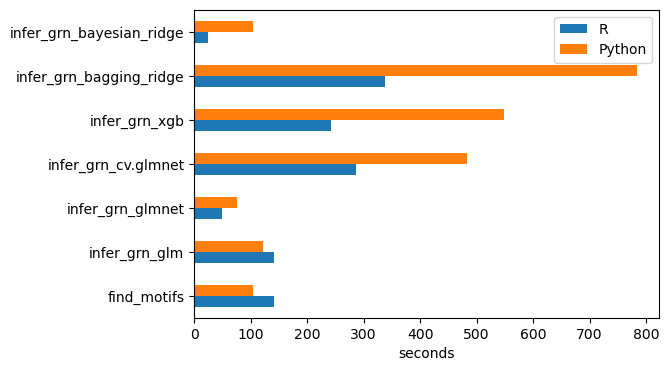

In [11]:
keys = ["find_motifs", "infer_grn_glm", "infer_grn_glmnet", "infer_grn_cv.glmnet", "infer_grn_xgb",
        "infer_grn_bagging_ridge", "infer_grn_bayesian_ridge"]
t = pd.DataFrame({"R": [rrun["timing"].get(k, np.nan) for k in keys], "Python": [ptime.get(k, np.nan) for k in keys]}, index=keys)
t["speed-up (R / Py)"] = (t.R / t.Python).round(2)
ax = t[["R", "Python"]].plot.barh(figsize=(6, 4)); ax.set_xlabel("seconds")
t.round(1)

## 6. Verdict

In [12]:
verdict = pd.DataFrame([{"gate": k, "pass": v["pass"]} for k, v in res.items()])
print("PASS — all outputs cleared the pre-registered gate" if verdict["pass"].all() else
      "FAIL — " + ", ".join(verdict.loc[~verdict["pass"], "gate"]) + " (see sections above and RECONSTRUCTION_REPORT.md)")
verdict

FAIL — xgb_gain (see sections above and RECONSTRUCTION_REPORT.md)


,gate,pass
0,candidate_regions,True
1,candidate_regions_phastcons,True
2,peaks_near_genes_signac,True
3,peaks_near_genes_great,True
4,motif_matrix,True
5,glm_keys,True
6,glm_coefficients,True
7,glm_pvalues,True
8,modules,True
9,glmnet_coefficients,True
